<a href="https://colab.research.google.com/github/ranishpriya396/pytorch-deep-learning/blob/main/Flower_CNN_Classification_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Flower Classification using a Simple CNN

This notebook trains a small Convolutional Neural Network (CNN) to classify five flower categories: daisy, dandelion, rose, sunflower, and tulip.

In [6]:
# Google Colab only
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
from PIL import Image

print("PyTorch version:", torch.__version__)


PyTorch version: 2.11.0+cpu


In [8]:
# Use GPU when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


## 1. Image preprocessing

In [9]:
data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [10]:
dataset_path = "/content/drive/MyDrive/flowers"

flower_dataset = datasets.ImageFolder(
    root=dataset_path,
    transform=data_transforms
)

class_names = flower_dataset.classes
num_classes = len(class_names)

print("Classes found:", class_names)
print("Mapping:", flower_dataset.class_to_idx)
print("Number of classes:", num_classes)
print("Total images:", len(flower_dataset))


Classes found: ['daisy', 'dandelion', 'rose', 'sunflower', 'tulip']
Mapping: {'daisy': 0, 'dandelion': 1, 'rose': 2, 'sunflower': 3, 'tulip': 4}
Number of classes: 5
Total images: 4317


## 2. Train/validation split

In [11]:
# 80% training, 20% validation
train_size = int(0.8 * len(flower_dataset))
val_size = len(flower_dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    flower_dataset,
    [train_size, val_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))


Training images: 3453
Validation images: 864


## 3. Visualize a batch

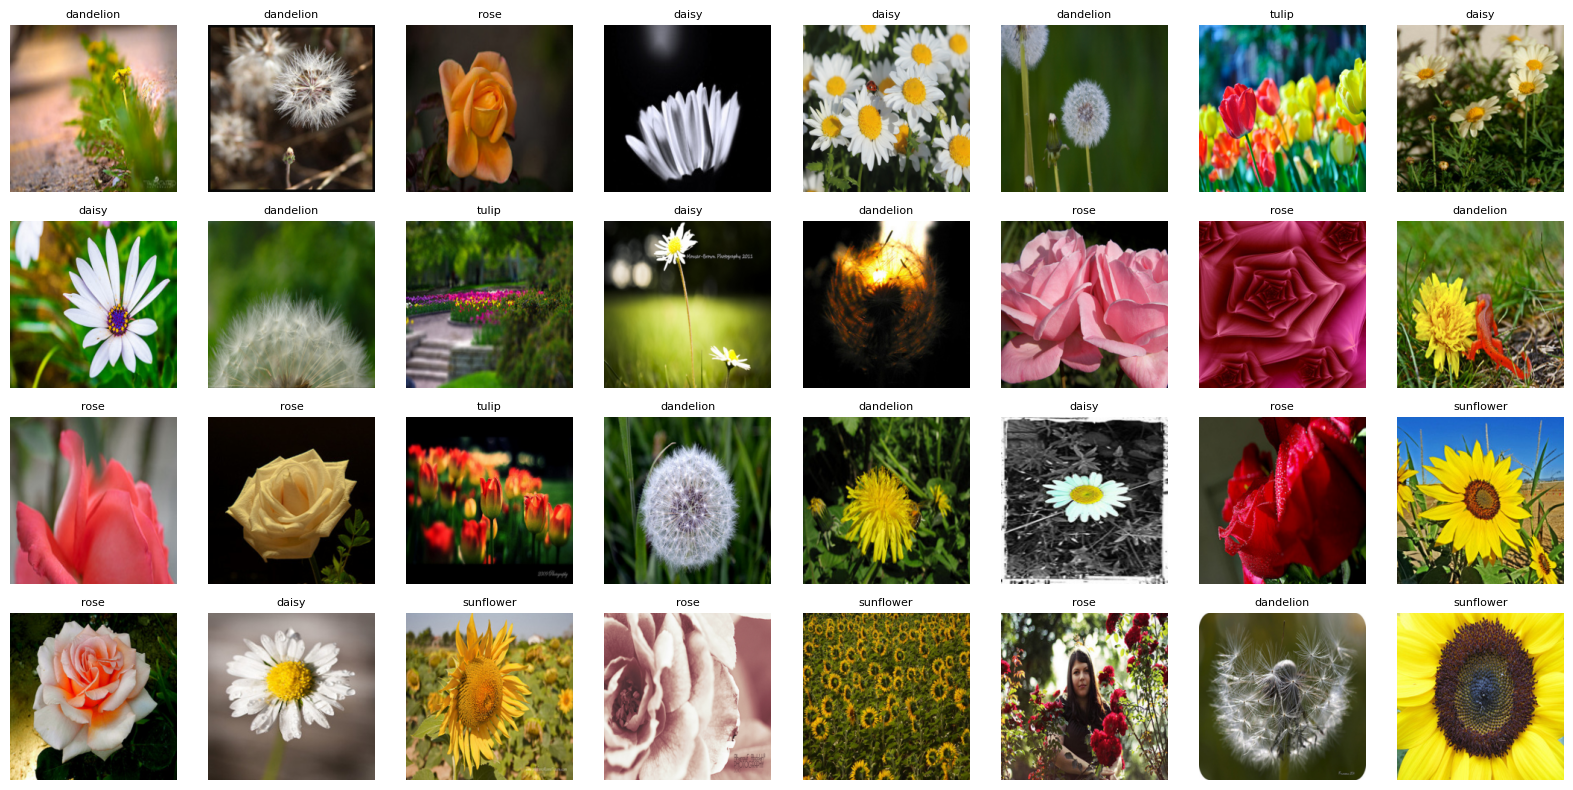

In [12]:
images, labels = next(iter(train_loader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes = axes.flatten()

for i in range(min(len(images), len(axes))):
    clean_tensor = (images[i] * std + mean).clamp(0, 1)

    axes[i].imshow(clean_tensor.permute(1, 2, 0))
    axes[i].set_title(class_names[labels[i].item()], fontsize=8)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


## 4. Define the CNN

In [14]:
class SimpleFlowerCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            # 224x224 -> 112x112
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 112x112 -> 56x56
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 56x56 -> 28x28
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SimpleFlowerCNN(num_classes).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print(model)


SimpleFlowerCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50176, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=5, bias=True)
  )
)


## 5. Training and validation

In [15]:
num_epochs = 10

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

print("Starting training...")

for epoch in range(num_epochs):
    # --------------------
    # Training
    # --------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # --------------------
    # Validation
    # --------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = 100 * val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("Training completed successfully!")


Starting training...
Epoch [1/10] | Train Loss: 1.2977 | Train Acc: 45.12% | Val Loss: 1.1559 | Val Acc: 55.09%
Epoch [2/10] | Train Loss: 0.9817 | Train Acc: 61.28% | Val Loss: 1.0461 | Val Acc: 58.45%
Epoch [3/10] | Train Loss: 0.7826 | Train Acc: 69.65% | Val Loss: 1.0048 | Val Acc: 61.92%
Epoch [4/10] | Train Loss: 0.5068 | Train Acc: 82.04% | Val Loss: 1.1663 | Val Acc: 60.88%
Epoch [5/10] | Train Loss: 0.2466 | Train Acc: 91.83% | Val Loss: 1.4195 | Val Acc: 63.43%
Epoch [6/10] | Train Loss: 0.1201 | Train Acc: 96.15% | Val Loss: 1.8145 | Val Acc: 60.19%
Epoch [7/10] | Train Loss: 0.0624 | Train Acc: 98.12% | Val Loss: 2.0511 | Val Acc: 61.92%
Epoch [8/10] | Train Loss: 0.0479 | Train Acc: 98.81% | Val Loss: 2.3937 | Val Acc: 61.69%
Epoch [9/10] | Train Loss: 0.0502 | Train Acc: 98.58% | Val Loss: 1.9269 | Val Acc: 61.81%
Epoch [10/10] | Train Loss: 0.0486 | Train Acc: 98.73% | Val Loss: 2.4711 | Val Acc: 58.91%
Training completed successfully!


## 6. Plot learning curves

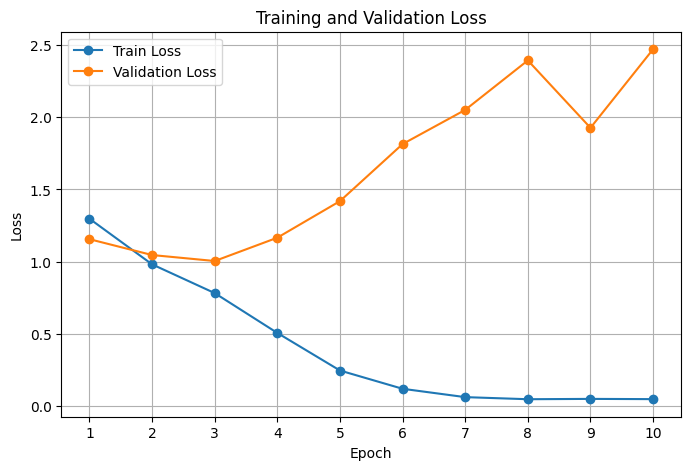

In [16]:
epochs_range = range(1, num_epochs + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.show()


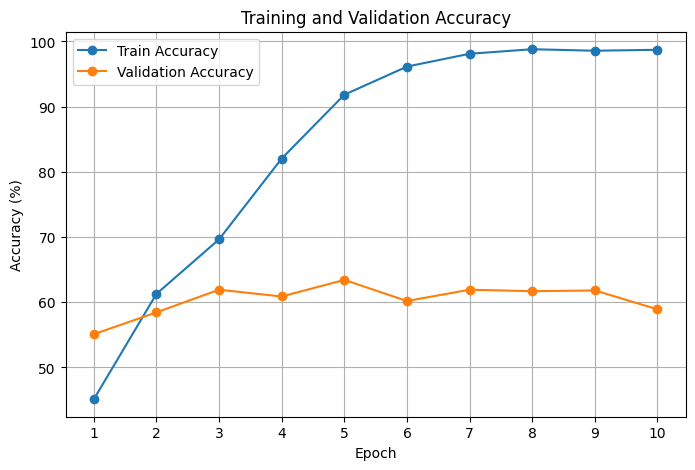

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history["train_accuracy"], marker="o", label="Train Accuracy")
plt.plot(epochs_range, history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.show()


## 7. Save the trained model

In [18]:
model_save_path = "/content/drive/MyDrive/simple_flower_cnn.pth"

torch.save(model.state_dict(), model_save_path)

print(f"Model weights saved to: {model_save_path}")


Model weights saved to: /content/drive/MyDrive/simple_flower_cnn.pth


## 8. Load the trained model

In [19]:
loaded_model = SimpleFlowerCNN(num_classes=num_classes).to(device)

loaded_weights = torch.load(
    model_save_path,
    map_location=device
)

loaded_model.load_state_dict(loaded_weights)
loaded_model.eval()

print("Model loaded successfully.")


Model loaded successfully.


## 9. Single-image inference

In [20]:
def predict_single_image(image_path, model, transform, class_names, device):
    image = Image.open(image_path).convert("RGB")

    image_tensor = transform(image).unsqueeze(0).to(device)

    model.eval()

    with torch.no_grad():
        outputs = model(image_tensor)
        probabilities = torch.softmax(outputs, dim=1)

        confidence, predicted_idx = torch.max(probabilities, dim=1)

    predicted_class = class_names[predicted_idx.item()]
    confidence_value = confidence.item() * 100

    print("Prediction Result:")
    print(f"Category: {predicted_class}")
    print(f"Confidence: {confidence_value:.2f}%")

    return predicted_class, confidence_value


# Example:
# predict_single_image(
#     "/content/drive/MyDrive/test_flower.jpg",
#     loaded_model,
#     data_transforms,
#     class_names,
#     device
# )
